<a href="https://colab.research.google.com/github/mareylugo/ICD-2026/blob/Practicas/Practica2_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Introducción a la Ciencia de Datos 2026**
Posgrado en Ciencias de la Computación - CICESE  
Práctica 2: Procesamiento de datatasets

Luz Marey Lugo Acedo

# Introducción
El cáncer cervical o de cuello uterino es el quinto cancer más común en mujeres alrededor del mundo según la OMS[1], el riesgo de desarrollar este cáncer es reducible y si es detectado a tiempo puede tratarse y curarse en su totalidad. La mayor causa son las lesiones causadas por el virus del papiloma humano. Las tasas de mortalidad más altas son entre las mujeres de clase a media y baja debido a la falta de acceso a la salud y a la detección tardía. En 2024 hubieron 280 000 muertes.   

 El presente Dataset es el resultado de un censado de factores de riesgo para cáncer cervical en el Hospital Universitario de Caracas, en donde se cubre historial médico de las pacientes, información demográfica y hábitos, por ejemplo, si fuman o si han tenido alguna enfermedad de transmisión sexual, así como los resultados de sus estudios médicos para detectar dicho diagnóstico. Hay información faltante ya que hay preguntas que las pacientes decidieron no responder, estos datos se registraron con un signo de interrogación (?). Contiene 858 registros y 36 atributos. [2]  
 Las cuatro variables objetivo son las de los siguientes estudios que se realizan para evaluar lesiones cancerosas o pre-cancerosas: Cytología, Hinselmann, Schiller y Biopsia. En el registro se marcan como 0 las que los médicos evaluaron como negativas, mientras que las positivas (o anormales) se marcaron con 1. [3]

 Para esta práctica se utilizaron las siguientes téctnicas de preprocesamiento de datos sobre este dataset: una exploración en conjunto de técnicas de limpieza de datos, en donde se eliminaron duplicados y se eliminaron atributos casi vacíos que no aportaban información, aumento de datos, extracción de características, reducción de dimensionalidad y selección de características.


# Analisis exploratorio y limpieza de datos

In [1]:
# Se cargan librerias que se van a usar
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

#cargar el dataset en en un dataframe de pandas llamado df
df = pd.read_csv('https://raw.githubusercontent.com/mareylugo/ICD-2026/Practicas/risk_factors_cervical_cancer.csv')
# Uso de funciones relacionadas a las dimensiones del dataframe.
print(f"Dimensiones del DataFrame: {df.shape[0]} Instances, {df.shape[1]} Features")

# Imprimir la información del dataframe
print("\nInformación del DataFrame:")
df.info()


Dimensiones del DataFrame: 858 Instances, 36 Features

Información del DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 858 entries, 0 to 857
Data columns (total 36 columns):
 #   Column                              Non-Null Count  Dtype 
---  ------                              --------------  ----- 
 0   Age                                 858 non-null    int64 
 1   Number of sexual partners           858 non-null    object
 2   First sexual intercourse            858 non-null    object
 3   Num of pregnancies                  858 non-null    object
 4   Smokes                              858 non-null    object
 5   Smokes (years)                      858 non-null    object
 6   Smokes (packs/year)                 858 non-null    object
 7   Hormonal Contraceptives             858 non-null    object
 8   Hormonal Contraceptives (years)     858 non-null    object
 9   IUD                                 858 non-null    object
 10  IUD (years)                         858 

In [2]:
#Sección para revisar cantidad de atributos categóricos y ubicar cuáles son.
categorical_attributes = []

for col in df.columns:
    # Reemplazo de ? por NaN para evaluar solo los 0 y 1
    temp_series = df[col].replace('?', np.nan)

    #   Tratar de cambiar otros formatos a numerico.
    try:
        numeric_series = pd.to_numeric(temp_series)
        unique_vals = numeric_series.dropna().unique()

        # Revisar si los valores en cada atributo se encuentran conformados por ceros y unos
        if set(unique_vals).issubset({0.0, 1.0}):
            categorical_attributes.append(col)
    except ValueError:
        # Si no es una columna numérica, se la salta
        continue

print("Categorical Attributes (0 and 1 only):")
for attr in categorical_attributes:
    print(f"- {attr}")
print(f"Quantity of categorical attributes {len(categorical_attributes)}")

continuous_attributes = []

for col in df.columns:
    # Reemplazo de ? por NaN
    temp_series = df[col].replace('?', np.nan)

    try:
        numeric_series = pd.to_numeric(temp_series)
        # revisar si una columna tiene mas de dos variables ignorando el NaN, o si se encuentra como float
        unique_vals_non_nan = numeric_series.dropna().unique()

        # Exclusión de las categorías que se guardaron como categóricas
        if col not in categorical_attributes:
            #Si el contenido es númerico y tiene más de dos variables o se encuentra
            #guardado como float, lo más probable es que este conformado este atributo como número continuo.
            # Se usan > 2 valores únicos para distinguir de valores Integer que no sean 0 y 1 y
            # sean discretos aunque no sean continuos en el sentido de que tengan decimales, o en su caso sean float
            if len(unique_vals_non_nan) > 2 or pd.api.types.is_float_dtype(numeric_series.dtype):
                continuous_attributes.append(col)
    except ValueError:
        continue

print("Continuous Attributes:")
for attr in continuous_attributes:
    print(f"- {attr}")

print(f"Quantity of continuous attributes: {len(continuous_attributes)}")

Categorical Attributes (0 and 1 only):
- Smokes
- Hormonal Contraceptives
- IUD
- STDs
- STDs:condylomatosis
- STDs:cervical condylomatosis
- STDs:vaginal condylomatosis
- STDs:vulvo-perineal condylomatosis
- STDs:syphilis
- STDs:pelvic inflammatory disease
- STDs:genital herpes
- STDs:molluscum contagiosum
- STDs:AIDS
- STDs:HIV
- STDs:Hepatitis B
- STDs:HPV
- Dx:Cancer
- Dx:CIN
- Dx:HPV
- Dx
- Hinselmann
- Schiller
- Citology
- Biopsy
Quantity of categorical attributes 24
Continuous Attributes:
- Age
- Number of sexual partners
- First sexual intercourse
- Num of pregnancies
- Smokes (years)
- Smokes (packs/year)
- Hormonal Contraceptives (years)
- IUD (years)
- STDs (number)
- STDs: Number of diagnosis
- STDs: Time since first diagnosis
- STDs: Time since last diagnosis
Quantity of continuous attributes: 12


In [3]:
# Imprime la cantidad de ? que hay en cada uno de los atributos
print("Quantity of '?' in each attribute:")
for col in df.columns:
    question_mark_count = (df[col] == '?').sum()
    if question_mark_count > 0:
        print(f"- {col}: {int(question_mark_count)}")
    else:
        print(f"- {col}: No '?' values")

Quantity of '?' in each attribute:
- Age: No '?' values
- Number of sexual partners: 26
- First sexual intercourse: 7
- Num of pregnancies: 56
- Smokes: 13
- Smokes (years): 13
- Smokes (packs/year): 13
- Hormonal Contraceptives: 108
- Hormonal Contraceptives (years): 108
- IUD: 117
- IUD (years): 117
- STDs: 105
- STDs (number): 105
- STDs:condylomatosis: 105
- STDs:cervical condylomatosis: 105
- STDs:vaginal condylomatosis: 105
- STDs:vulvo-perineal condylomatosis: 105
- STDs:syphilis: 105
- STDs:pelvic inflammatory disease: 105
- STDs:genital herpes: 105
- STDs:molluscum contagiosum: 105
- STDs:AIDS: 105
- STDs:HIV: 105
- STDs:Hepatitis B: 105
- STDs:HPV: 105
- STDs: Number of diagnosis: No '?' values
- STDs: Time since first diagnosis: 787
- STDs: Time since last diagnosis: 787
- Dx:Cancer: No '?' values
- Dx:CIN: No '?' values
- Dx:HPV: No '?' values
- Dx: No '?' values
- Hinselmann: No '?' values
- Schiller: No '?' values
- Citology: No '?' values
- Biopsy: No '?' values


In [4]:
# Eliminar las dos columnas casi vacías
cols_to_drop = ['STDs: Time since first diagnosis', 'STDs: Time since last diagnosis']
df = df.drop(columns=cols_to_drop)

print(f"Dimensiones del DataFrame: {df.shape[0]} Instances, {df.shape[1]} Features")
continuous_attributes = [c for c in continuous_attributes if c not in cols_to_drop]
print(f"Quantity of continuous attributes: {len(continuous_attributes)}")

Dimensiones del DataFrame: 858 Instances, 34 Features
Quantity of continuous attributes: 10


In [5]:
# Buscar registros repetidos
n_duplicados = df.duplicated().sum()
print(f"Registros repetidos: {n_duplicados}")

# Ver los registros repetidos (todas las apariciones, agrupadas)
df[df.duplicated(keep=False)].sort_values(by=list(df.columns)).head(10)

# Eliminar los registros repetidos (se conserva la primera aparición)
df = df.drop_duplicates(keep='first').reset_index(drop=True)

print(f"Registros repetidos restantes: {df.duplicated().sum()}")
print(f"Dimensiones del DataFrame: {df.shape[0]} Instances, {df.shape[1]} Features")

Registros repetidos: 23
Registros repetidos restantes: 0
Dimensiones del DataFrame: 835 Instances, 34 Features


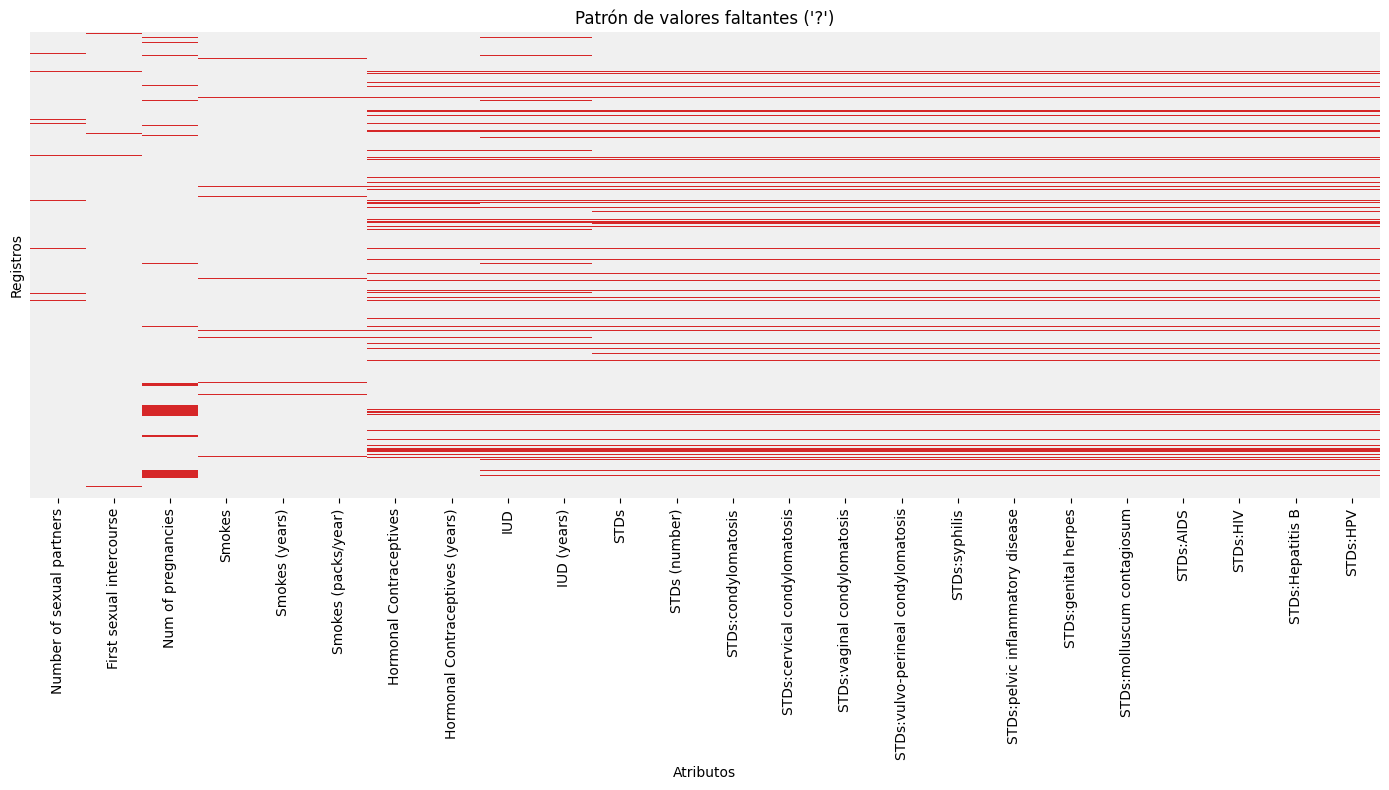

In [6]:
# Máscara de valores faltantes (True donde hay '?'), sin modificar df
mask_faltantes = (df == '?')

# Solo las columnas que tienen al menos un faltante, para que el mapa sea legible
cols_con_faltantes = mask_faltantes.columns[mask_faltantes.any()]

plt.figure(figsize=(14, 8))
sns.heatmap(mask_faltantes[cols_con_faltantes],
            cmap=['#f0f0f0', '#d62728'],  # gris = dato, rojo = faltante
            cbar=False,
            yticklabels=False)
plt.title("Patrón de valores faltantes ('?')")
plt.xlabel("Atributos")
plt.ylabel("Registros")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

Segun el heatmap de los valores faltantes, parece ser que la mayoria de datos faltantes son de los mismos registros.

In [7]:
objetivos = ['Hinselmann', 'Schiller', 'Citology', 'Biopsy']

mask_faltantes = (df == '?')

# Registros con al menos un objetivo positivo
pos_alguno = (df[objetivos] == 1).any(axis=1)
# Registros con al menos un '?'
con_faltantes = mask_faltantes.any(axis=1)

positivos_con_faltantes = df[pos_alguno & con_faltantes]
print(f"Positivos (algún objetivo): {pos_alguno.sum()}")
print(f"Positivos con algún '?': {len(positivos_con_faltantes)}")

positivos_con_faltantes

Positivos (algún objetivo): 101
Positivos con algún '?': 16


,Age,Number of sexual partners,First sexual intercourse,Num of pregnancies,Smokes,Smokes (years),Smokes (packs/year),Hormonal Contraceptives,Hormonal Contraceptives (years),IUD,...,STDs:HPV,STDs: Number of diagnosis,Dx:Cancer,Dx:CIN,Dx:HPV,Dx,Hinselmann,Schiller,Citology,Biopsy
41,37,2.0,18.0,?,0.0,0.0,0.0,0.0,0.0,?,...,0.0,1,0,1,0,1,0,1,0,1
95,35,5.0,11.0,?,1.0,15.0,15.0,1.0,14.0,0.0,...,0.0,0,0,0,0,0,1,1,1,1
130,30,?,13.0,3.0,1.0,22.0,3.3,0.0,0.0,0.0,...,0.0,1,0,0,0,0,1,1,0,1
184,28,2.0,17.0,?,0.0,0.0,0.0,1.0,9.0,0.0,...,0.0,0,0,0,0,0,1,1,0,1
342,22,4.0,16.0,1.0,0.0,0.0,0.0,1.0,0.5,0.0,...,?,0,0,0,0,0,0,1,0,1
414,26,3.0,15.0,?,0.0,0.0,0.0,1.0,0.33,?,...,0.0,0,0,0,0,0,1,1,0,1
427,16,3.0,14.0,1.0,0.0,0.0,0.0,?,?,?,...,?,0,0,0,0,0,0,0,1,0
444,15,3.0,14.0,1.0,1.0,1.266972909,0.5132021277,?,?,?,...,?,0,0,0,0,0,0,0,1,0
632,21,1.0,17.0,?,0.0,0.0,0.0,1.0,3.0,0.0,...,0.0,0,0,1,0,1,0,0,0,1
648,38,3.0,22.0,2.0,?,?,?,1.0,3.0,1.0,...,0.0,0,1,0,1,1,0,1,0,0


Debido a la poca representación que hay de valores positivos, revisamos cuales de estos les falta información para empezar a evaluar cuales atributos valdría la pena aumentar o imputar, o simplemente desechar por su mala calidad.

In [8]:
resumen = []
for obj in objetivos:
    pos = df[obj] == 1
    resumen.append({
        'Objetivo': obj,
        'Positivos': pos.sum(),
        'Positivos con algún ?': (pos & con_faltantes).sum(),
        '% con ?': round(100 * (pos & con_faltantes).sum() / pos.sum(), 1)
    })

pd.DataFrame(resumen)

,Objetivo,Positivos,Positivos con algún ?,% con ?
0,Hinselmann,35,5,14.3
1,Schiller,73,11,15.1
2,Citology,43,5,11.6
3,Biopsy,54,10,18.5


In [9]:
faltantes_en_positivos = mask_faltantes[pos_alguno].sum()
faltantes_en_positivos[faltantes_en_positivos > 0].sort_values(ascending=False)

,0
Num of pregnancies,9
IUD (years),6
IUD,6
STDs (number),5
STDs,5
STDs:cervical condylomatosis,5
STDs:condylomatosis,5
STDs:syphilis,5
STDs:pelvic inflammatory disease,5
STDs:genital herpes,5


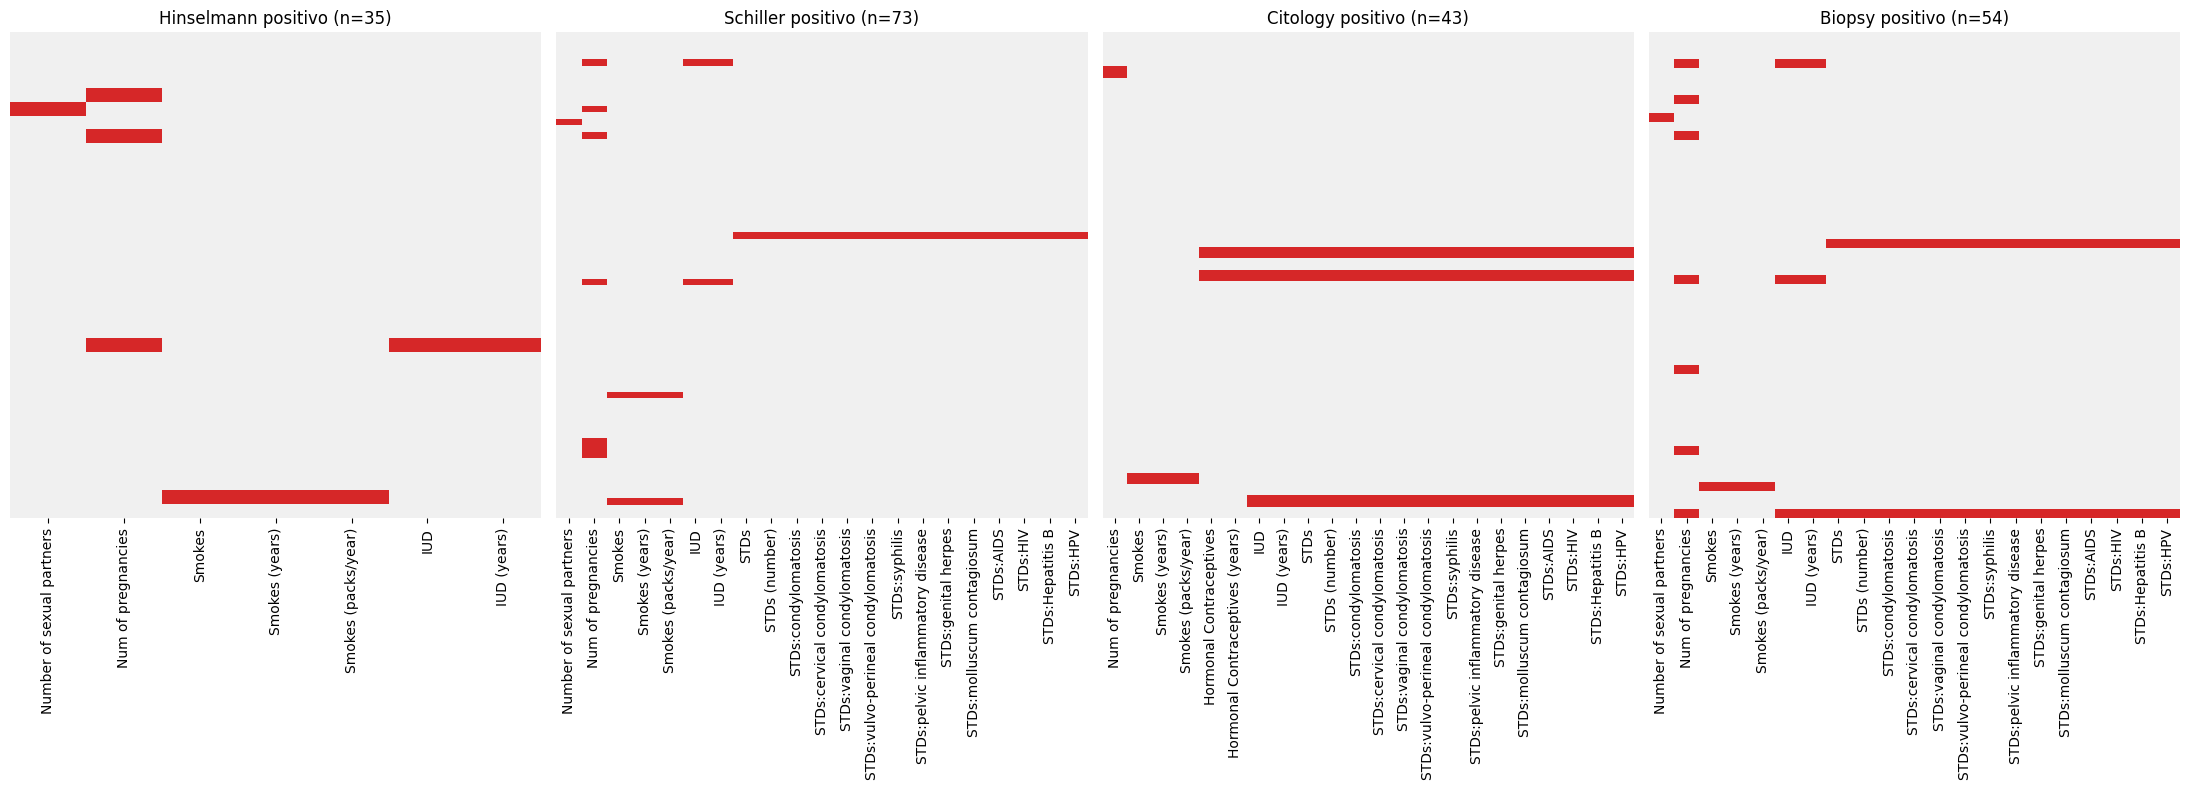

In [10]:
#Heatmap de faltantes por cada variable objetivo
fig, axes = plt.subplots(1, 4, figsize=(22, 8), sharey=False)

for ax, obj in zip(axes, objetivos):
    pos = df[obj] == 1
    m = mask_faltantes[pos]
    cols = m.columns[m.any()]
    sns.heatmap(m[cols], cmap=['#f0f0f0', '#d62728'], cbar=False,
                yticklabels=False, ax=ax)
    ax.set_title(f"{obj} positivo (n={pos.sum()})")
    ax.tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

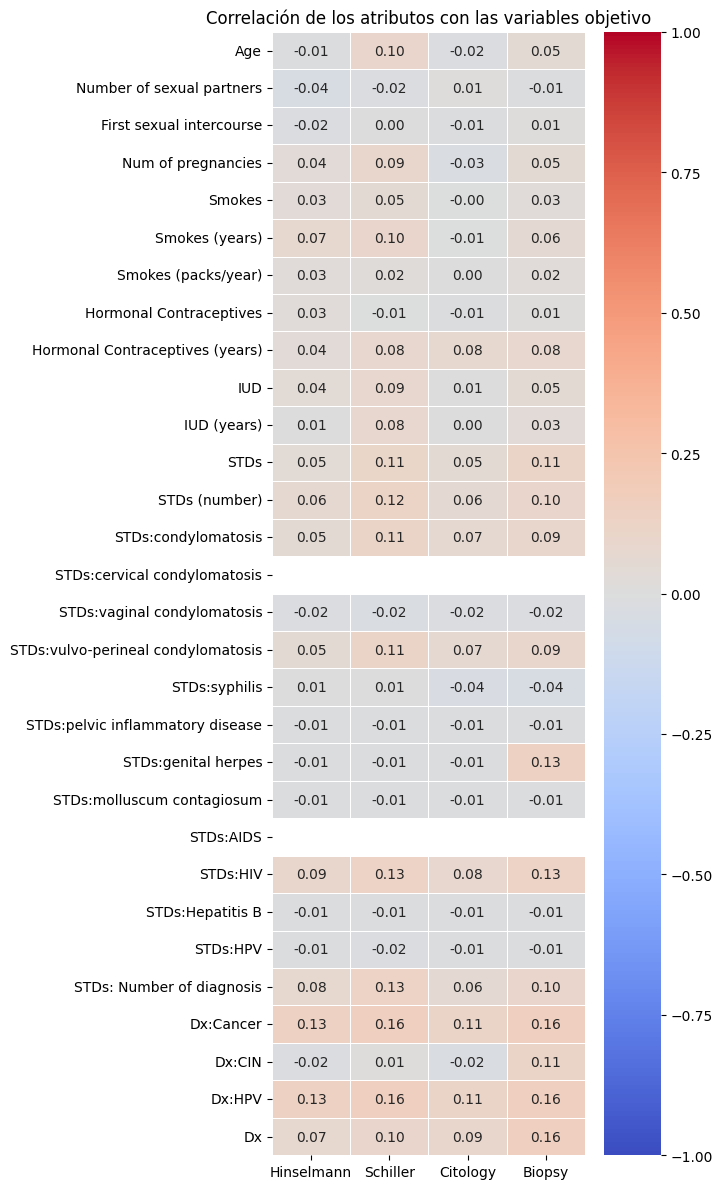

In [11]:
objetivos = ['Hinselmann', 'Schiller', 'Citology', 'Biopsy']

# Copia numérica temporal (df no se modifica)
df_num = df.replace('?', np.nan).apply(pd.to_numeric)

# Correlación de todos los atributos contra las cuatro variables objetivo
corr = df_num.corr()
corr_obj = corr.loc[[c for c in corr.index if c not in objetivos], objetivos]

plt.figure(figsize=(7, 12))
sns.heatmap(corr_obj, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, center=0, linewidths=0.5)
plt.title("Correlación de los atributos con las variables objetivo")
plt.tight_layout()
plt.show()

# Aumento de datos

**Preparación para el aumento de datos.** Para aumentar datos necesitamos que no haya `?`, así que a partir de aquí se trabaja sobre una copia numérica (`df_num`). El orden es importante para evitar fuga de información (*data leakage*):

1. Se construye la variable objetivo única `Cancer_precancer` (1 si al menos uno de los cuatro estudios es positivo).
2. Se separa en entrenamiento (80%) y prueba (20%), estratificando por la clase.
3. Se imputan los faltantes **ajustando el imputador solo con entrenamiento**: mediana para atributos numéricos y moda para los binarios.

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

objetivos = ['Hinselmann', 'Schiller', 'Citology', 'Biopsy']

# Copia numérica: los '?' pasan a NaN (df original no se modifica)
df_num = df.replace('?', np.nan).apply(pd.to_numeric)

# Variable objetivo única: positiva si al menos uno de los 4 estudios es positivo
df_num['Cancer_precancer'] = (df_num[objetivos] == 1).any(axis=1).astype(int)

y = df_num['Cancer_precancer']
# Las 4 variables objetivo originales NO pueden ser predictoras (definen directamente a y)
X = df_num.drop(columns=objetivos + ['Cancer_precancer'])

# Atributos binarios y numéricos (usando las listas de la sección de limpieza)
bin_cols = [c for c in categorical_attributes if c in X.columns]
num_cols = [c for c in X.columns if c not in bin_cols]

print(f"Atributos binarios: {len(bin_cols)} | numéricos: {len(num_cols)}")
print("Distribución de Cancer_precancer:")
print(y.value_counts().to_string())
print((y.value_counts(normalize=True) * 100).round(1).to_string())

Atributos binarios: 20 | numéricos: 10
Distribución de Cancer_precancer:
Cancer_precancer
0    734
1    101
Cancer_precancer
0    87.9
1    12.1


In [13]:
# Separación entrenamiento / prueba (estratificada)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# Imputación: se ajusta SOLO con entrenamiento
imp_bin = SimpleImputer(strategy='most_frequent').fit(X_train[bin_cols])
imp_num = SimpleImputer(strategy='median').fit(X_train[num_cols])

def imputar(d):
    d = d.copy()
    d[bin_cols] = imp_bin.transform(d[bin_cols])
    d[num_cols] = imp_num.transform(d[num_cols])
    return d

X_train = imputar(X_train)
X_test = imputar(X_test)

print("Faltantes restantes en entrenamiento:", int(X_train.isna().sum().sum()))
print("Faltantes restantes en prueba:", int(X_test.isna().sum().sum()))
print(f"Entrenamiento: {X_train.shape} | Prueba: {X_test.shape}")
print("Positivos en entrenamiento:", int(y_train.sum()), "| en prueba:", int(y_test.sum()))

Faltantes restantes en entrenamiento: 0
Faltantes restantes en prueba: 0
Entrenamiento: (668, 30) | Prueba: (167, 30)
Positivos en entrenamiento: 81 | en prueba: 20


**Aumento con SMOTENC.** Los positivos son una clase muy minoritaria. SMOTENC genera registros sintéticos de la clase minoritaria interpolando entre vecinos cercanos, y a diferencia de SMOTE clásico maneja por separado los atributos categóricos (0/1), de modo que no aparecen valores como `Smokes = 0.37`. Se aplica **solo al conjunto de entrenamiento**; el de prueba se conserva con datos reales.

Antes del aumento: {0: 587, 1: 81}
Después del aumento: {0: 587, 1: 587}


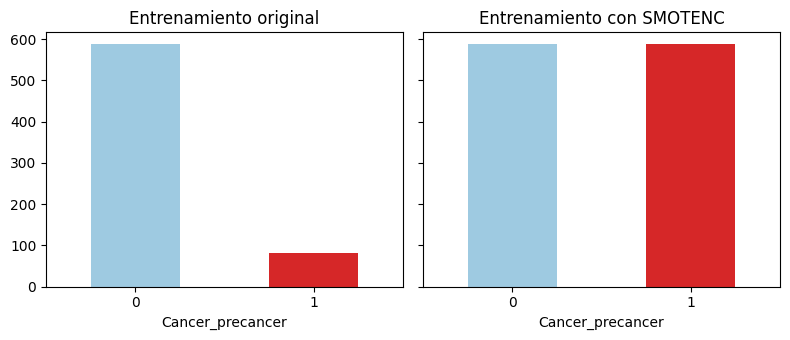

In [14]:
from imblearn.over_sampling import SMOTENC

cat_idx = [X_train.columns.get_loc(c) for c in bin_cols]

smote = SMOTENC(categorical_features=cat_idx, random_state=42)
X_train_aug, y_train_aug = smote.fit_resample(X_train, y_train)

# Los atributos que son conteos enteros se redondean para que los sintéticos sean plausibles
conteos = ['Age', 'Number of sexual partners', 'First sexual intercourse',
           'Num of pregnancies', 'STDs (number)', 'STDs: Number of diagnosis']
X_train_aug[conteos] = X_train_aug[conteos].round()
X_train_aug[bin_cols] = X_train_aug[bin_cols].round().astype(int)

print("Antes del aumento:", y_train.value_counts().to_dict())
print("Después del aumento:", pd.Series(y_train_aug).value_counts().to_dict())

fig, axes = plt.subplots(1, 2, figsize=(8, 3.5), sharey=True)
y_train.value_counts().sort_index().plot(kind='bar', ax=axes[0], color=['#9ecae1', '#d62728'])
axes[0].set_title("Entrenamiento original")
pd.Series(y_train_aug).value_counts().sort_index().plot(kind='bar', ax=axes[1], color=['#9ecae1', '#d62728'])
axes[1].set_title("Entrenamiento con SMOTENC")
for ax in axes:
    ax.set_xlabel("Cancer_precancer"); ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

In [15]:
# Revisión de plausibilidad: ¿los sintéticos respetan relaciones lógicas básicas?
reales = X_train
sinteticos = X_train_aug.iloc[len(X_train):]

def incoherentes(d):
    return int((d['First sexual intercourse'] > d['Age']).sum())

print(f"Primera relación sexual > edad  | reales: {incoherentes(reales)} de {len(reales)}"
      f" | sintéticos: {incoherentes(sinteticos)} de {len(sinteticos)}")

# Comparación de medias entre registros positivos reales y sintéticos
comp = pd.DataFrame({
    'positivos reales': X_train[y_train == 1][num_cols].mean(),
    'sintéticos': sinteticos[num_cols].mean()
}).round(2)
comp

Primera relación sexual > edad  | reales: 2 de 668 | sintéticos: 0 de 506


,positivos reales,sintéticos
Age,27.51,26.93
Number of sexual partners,2.47,2.41
First sexual intercourse,16.79,16.59
Num of pregnancies,2.48,2.40
Smokes (years),2.07,1.49
Smokes (packs/year),0.39,0.29
Hormonal Contraceptives (years),2.33,2.09
IUD (years),0.81,0.60
STDs (number),0.36,0.28
STDs: Number of diagnosis,0.21,0.15


# Extracción de características


**Extracción (construcción) de características.** A partir de los atributos originales se construyen variables nuevas con reglas definidas desde el dominio, para resumir información que los modelos no ven directamente:

- `Years_sexually_active`: edad menos edad de la primera relación sexual (tiempo de exposición).
- `Partners_per_year_active`: parejas sexuales por año de actividad sexual.
- `STDs_types_count`: número de tipos distintos de ETS reportados.
- `Any_contraceptive`: usa anticonceptivos hormonales o DIU.
- `Smoking_years_ratio`: proporción de la vida que ha fumado.

Son cálculos fila por fila, sin parámetros aprendidos, así que se pueden aplicar igual a entrenamiento y prueba sin fuga de información. La variable objetivo única `Cancer_precancer` (agregación OR de los cuatro estudios) es otra construcción de atributos, hecha antes.

In [16]:
def agregar_features(d):
    d = d.copy()
    stds_tipos = [c for c in d.columns
                  if c.startswith('STDs:') and c != 'STDs: Number of diagnosis']
    d['Years_sexually_active'] = (d['Age'] - d['First sexual intercourse']).clip(lower=0)
    d['Partners_per_year_active'] = (d['Number of sexual partners']
                                     / d['Years_sexually_active'].clip(lower=1))
    d['STDs_types_count'] = d[stds_tipos].sum(axis=1)
    d['Any_contraceptive'] = ((d['Hormonal Contraceptives'] == 1) | (d['IUD'] == 1)).astype(int)
    d['Smoking_years_ratio'] = d['Smokes (years)'] / d['Age']
    return d

nuevas = ['Years_sexually_active', 'Partners_per_year_active', 'STDs_types_count',
          'Any_contraceptive', 'Smoking_years_ratio']

X_train_real_ext = agregar_features(X_train)       # entrenamiento sin aumento
X_train_ext = agregar_features(X_train_aug)        # entrenamiento aumentado
X_test_ext = agregar_features(X_test)

# Correlación de las nuevas variables con el objetivo (datos reales de entrenamiento)
corr_nuevas = X_train_real_ext[nuevas].corrwith(y_train).round(3)
print("Correlación con Cancer_precancer (entrenamiento real):")
print(corr_nuevas.to_string())
print(f"\nAtributos: {X_train.shape[1]} originales + {len(nuevas)} nuevos = {X_train_ext.shape[1]}")
X_train_ext[nuevas].describe().round(2)

Correlación con Cancer_precancer (entrenamiento real):
Years_sexually_active       0.035
Partners_per_year_active    0.017
STDs_types_count            0.134
Any_contraceptive          -0.039
Smoking_years_ratio         0.047

Atributos: 30 originales + 5 nuevos = 35


,Years_sexually_active,Partners_per_year_active,STDs_types_count,Any_contraceptive,Smoking_years_ratio
count,1174.00,1174.00,1174.00,1174.00,1174.00
mean,10.13,0.47,0.11,0.74,0.04
std,8.31,0.55,0.46,0.44,0.12
min,0.00,0.02,0.00,0.00,0.00
25%,4.00,0.17,0.00,0.00,0.00
50%,8.00,0.29,0.00,1.00,0.00
75%,14.00,0.56,0.00,1.00,0.00
max,64.00,5.00,4.00,1.00,0.79


# Reducción de dimensionalidad


**Reducción de dimensionalidad con PCA.** PCA transforma los atributos en componentes principales ortogonales que concentran la varianza. Requiere atributos en la misma escala, por lo que primero se estandarizan. Tanto el escalador como el PCA se ajustan solo con el entrenamiento; se elige el menor número de componentes que explique al menos 90% de la varianza.

Componentes necesarios para explicar >= 90% de la varianza: 18 de 35


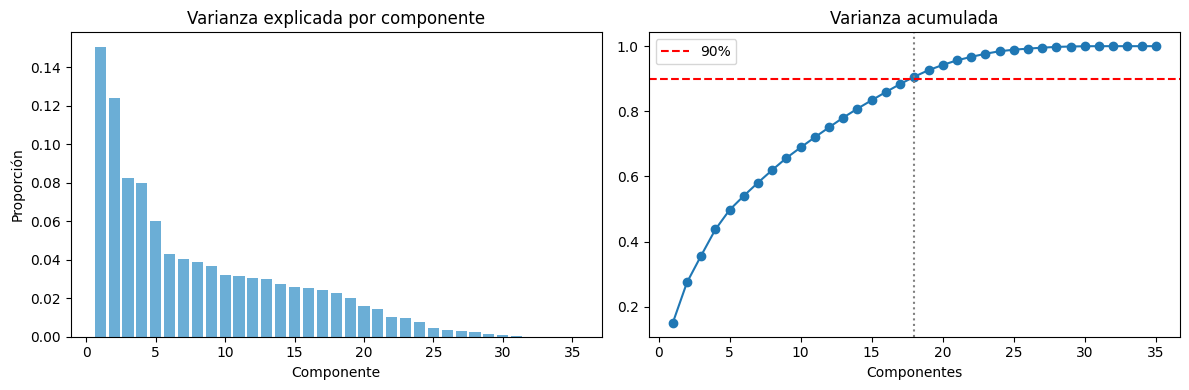

In [17]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

scaler = StandardScaler().fit(X_train_ext)
Z_train = scaler.transform(X_train_ext)
Z_test = scaler.transform(X_test_ext)

pca_full = PCA(random_state=42).fit(Z_train)
var_acum = np.cumsum(pca_full.explained_variance_ratio_)
n_comp = int(np.argmax(var_acum >= 0.90) + 1)
print(f"Componentes necesarios para explicar >= 90% de la varianza: {n_comp} de {Z_train.shape[1]}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(range(1, len(var_acum) + 1), pca_full.explained_variance_ratio_, color='#6baed6')
axes[0].set_title("Varianza explicada por componente")
axes[0].set_xlabel("Componente"); axes[0].set_ylabel("Proporción")
axes[1].plot(range(1, len(var_acum) + 1), var_acum, marker='o')
axes[1].axhline(0.90, color='r', linestyle='--', label='90%')
axes[1].axvline(n_comp, color='gray', linestyle=':')
axes[1].set_title("Varianza acumulada"); axes[1].set_xlabel("Componentes")
axes[1].legend()
plt.tight_layout()
plt.show()

Dimensiones tras PCA -> entrenamiento: (1174, 18) | prueba: (167, 18)


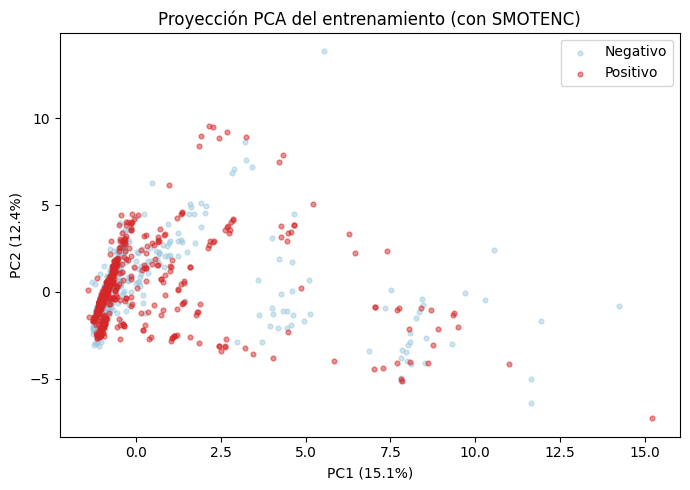

Mayores cargas en PC1:
STDs_types_count                      0.402
STDs                                  0.387
STDs:condylomatosis                   0.361
STDs:vulvo-perineal condylomatosis    0.357
STDs (number)                         0.347
STDs: Number of diagnosis             0.322

Mayores cargas en PC2:
Years_sexually_active       0.389
Age                         0.378
Num of pregnancies          0.318
Smokes (years)              0.312
Smoking_years_ratio         0.269
Partners_per_year_active    0.233


In [18]:
pca = PCA(n_components=n_comp, random_state=42).fit(Z_train)
P_train = pca.transform(Z_train)
P_test = pca.transform(Z_test)
print(f"Dimensiones tras PCA -> entrenamiento: {P_train.shape} | prueba: {P_test.shape}")

# Proyección en los dos primeros componentes
plt.figure(figsize=(7, 5))
for clase, color, nombre in [(0, '#9ecae1', 'Negativo'), (1, '#d62728', 'Positivo')]:
    idx = np.asarray(y_train_aug) == clase
    plt.scatter(P_train[idx, 0], P_train[idx, 1], s=12, alpha=0.5, c=color, label=nombre)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.title("Proyección PCA del entrenamiento (con SMOTENC)")
plt.legend()
plt.tight_layout()
plt.show()

# Atributos que más pesan en los dos primeros componentes
cargas = pd.DataFrame(pca.components_[:2].T, index=X_train_ext.columns, columns=['PC1', 'PC2'])
print("Mayores cargas en PC1:")
print(cargas['PC1'].abs().sort_values(ascending=False).head(6).round(3).to_string())
print("\nMayores cargas en PC2:")
print(cargas['PC2'].abs().sort_values(ascending=False).head(6).round(3).to_string())

# Selección de características


**Selección de características.** A diferencia de PCA, aquí se conserva un subconjunto de los atributos originales (más las nuevas), lo que mantiene la interpretabilidad. Se combinan dos criterios:

- **Filtro:** información mutua entre cada atributo y la variable objetivo.
- **Embebido:** importancia de atributos de un Random Forest.

Se promedia la posición (ranking) de cada atributo en ambos criterios y se conservan los 10 mejores. Antes se descartan los atributos constantes. Todo se ajusta solo con el entrenamiento.

Atributos constantes descartados: ['STDs:cervical condylomatosis', 'STDs:AIDS']

Atributos seleccionados (top 10):
- Hormonal Contraceptives (years)
- First sexual intercourse
- Age
- Partners_per_year_active
- Smokes (years)
- STDs (number)
- Years_sexually_active
- Smokes (packs/year)
- IUD (years)
- Number of sexual partners


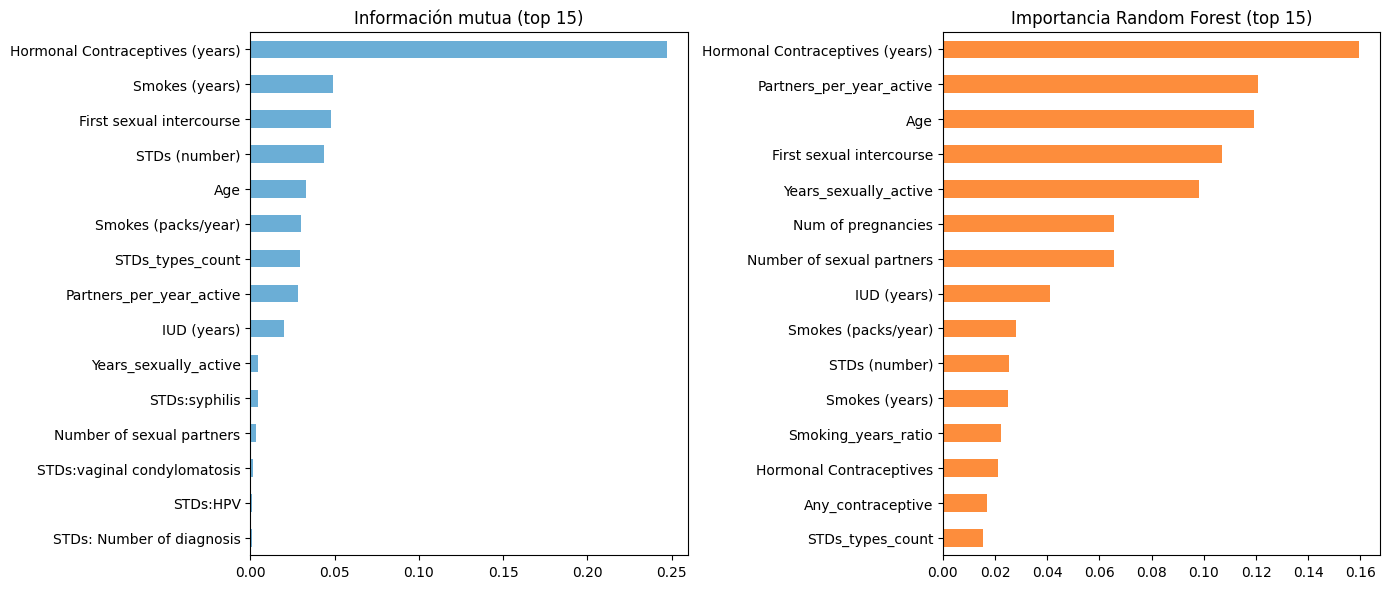

,info_mutua,imp_RF,pos_MI,pos_RF,pos_promedio
Hormonal Contraceptives (years),0.247,0.160,1.0,1.0,1.0
First sexual intercourse,0.048,0.107,3.0,4.0,3.5
Age,0.033,0.119,5.0,3.0,4.0
Partners_per_year_active,0.028,0.121,8.0,2.0,5.0
Smokes (years),0.049,0.025,2.0,11.0,6.5
STDs (number),0.044,0.025,4.0,10.0,7.0
Years_sexually_active,0.005,0.098,10.0,5.0,7.5
Smokes (packs/year),0.030,0.028,6.0,9.0,7.5
IUD (years),0.020,0.041,9.0,8.0,8.5
Number of sexual partners,0.003,0.065,12.0,7.0,9.5


In [19]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier

# 1) Descartar atributos constantes (varianza cero) en entrenamiento
constantes = [c for c in X_train_ext.columns if X_train_ext[c].nunique() <= 1]
print("Atributos constantes descartados:", constantes)
cols_candidatas = [c for c in X_train_ext.columns if c not in constantes]

# 2) Filtro: información mutua
binarias_ext = bin_cols + ['Any_contraceptive']
discretas = [c in binarias_ext for c in cols_candidatas]
mi = pd.Series(mutual_info_classif(X_train_ext[cols_candidatas], y_train_aug,
                                   discrete_features=discretas, random_state=42),
               index=cols_candidatas)

# 3) Embebido: importancia en Random Forest
rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
rf.fit(X_train_ext[cols_candidatas], y_train_aug)
imp_rf = pd.Series(rf.feature_importances_, index=cols_candidatas)

# 4) Ranking combinado (promedio de posiciones)
ranking = pd.DataFrame({
    'info_mutua': mi,
    'imp_RF': imp_rf,
    'pos_MI': mi.rank(ascending=False),
    'pos_RF': imp_rf.rank(ascending=False)
})
ranking['pos_promedio'] = ranking[['pos_MI', 'pos_RF']].mean(axis=1)
ranking = ranking.sort_values('pos_promedio')

K = 10
seleccionadas = ranking.head(K).index.tolist()
print(f"\nAtributos seleccionados (top {K}):")
for c in seleccionadas:
    print(f"- {c}")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
mi.sort_values().tail(15).plot(kind='barh', ax=axes[0], color='#6baed6')
axes[0].set_title("Información mutua (top 15)")
imp_rf.sort_values().tail(15).plot(kind='barh', ax=axes[1], color='#fd8d3c')
axes[1].set_title("Importancia Random Forest (top 15)")
plt.tight_layout()
plt.show()

ranking.head(15).round(3)

In [20]:
X_train_sel = X_train_ext[seleccionadas]
X_test_sel = X_test_ext[seleccionadas]
print(f"Dimensiones tras selección -> entrenamiento: {X_train_sel.shape} | prueba: {X_test_sel.shape}")

Dimensiones tras selección -> entrenamiento: (1174, 10) | prueba: (167, 10)


**Comparación de las técnicas.** Para comprobar el efecto de cada paso se entrena el mismo modelo (Random Forest) con cuatro versiones de los datos y se evalúa sobre el conjunto de prueba real. Con tan pocos positivos la prueba es pequeña, así que las diferencias son orientativas. Como las clases están muy desbalanceadas se usan *recall*, *precision* y AUC-PR (precisión promedio), no *accuracy*.

In [21]:
from sklearn.metrics import recall_score, precision_score, average_precision_score

def evaluar(nombre, Xtr, ytr, Xte):
    m = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(Xtr, ytr)
    pred = m.predict(Xte)
    prob = m.predict_proba(Xte)[:, 1]
    return {'Versión': nombre,
            'Atributos': Xtr.shape[1],
            'Recall': round(recall_score(y_test, pred), 3),
            'Precision': round(precision_score(y_test, pred, zero_division=0), 3),
            'AUC-PR': round(average_precision_score(y_test, prob), 3)}

resultados = pd.DataFrame([
    evaluar("Sin aumento, atributos originales", X_train, y_train, X_test),
    evaluar("Con SMOTENC + atributos nuevos", X_train_ext, y_train_aug, X_test_ext),
    evaluar("SMOTENC + selección (top 10)", X_train_sel, y_train_aug, X_test_sel),
    evaluar("SMOTENC + PCA", P_train, y_train_aug, P_test),
])
print(f"Línea base (proporción de positivos en prueba): {y_test.mean():.3f}")
resultados

Línea base (proporción de positivos en prueba): 0.120


,Versión,Atributos,Recall,Precision,AUC-PR
0,"Sin aumento, atributos originales",30,0.15,0.60,0.256
1,Con SMOTENC + atributos nuevos,35,0.20,0.20,0.216
2,SMOTENC + selección (top 10),10,0.20,0.16,0.187
3,SMOTENC + PCA,18,0.40,0.32,0.243


Limpieza y faltantes

Quedaron 835 registros y 34 atributos tras quitar 2 columnas casi vacías (92% de faltantes) y 23 duplicados.
Los faltantes vienen en bloques por pregunta del cuestionario (ETS, DIU, anticonceptivos, tabaquismo), no como valores sueltos. Solo 16 de los 101 positivos tenían algún ?, así que imputar fue mejor que descartar registros.

Aumento de datos

Con 81 positivos de 668 en entrenamiento, SMOTENC balanceó las clases a 587/587.
Los sintéticos son plausibles: ninguno tiene primera relación sexual a mayor edad que la actual (frente a 2 casos en los reales), y las medias son parecidas a las de los positivos reales. Hay una diferencia en las variables de tabaquismo y DIU (por ejemplo, Smokes (years) 1.49 contra 2.07), porque la interpolación acerca los valores hacia cero.

Extracción de características

Las 5 variables nuevas correlacionan poco con el objetivo. La mayor es STDs_types_count (0.134); Partners_per_year_active solo 0.017.

Reducción de dimensionalidad

PCA necesitó 18 de 35 componentes para el 90% de la varianza, así que la compresión fue modesta. PC1 resume las variables de ETS y PC2 la edad, los años de actividad sexual, los embarazos y el tabaquismo.

Comparación de técnicas (prueba con solo 20 positivos)

Versión	Recall	Precision	AUC-PR
Sin aumento	0.15	0.60	0.256
SMOTENC + atributos nuevos	0.20	0.20	0.216
SMOTENC + selección	0.20	0.16	0.187
SMOTENC + PCA	0.40	0.32	0.243
El aumento no mejoró el AUC-PR. La versión sin aumento tuvo el más alto (0.256) y la mejor precisión. SMOTENC subió algo el recall a costa de muchos más falsos positivos.
SMOTENC + PCA fue la versión con mejor recall (0.40, 8 de 20 positivos detectados) y un AUC-PR cercano al mejor. Es la única que ofrece un compromiso aceptable, aunque sigue por debajo de lo deseable para un tamizaje.
Todos los AUC-PR superan la línea base de 0.12, pero por poco (entre 1.5 y 2 veces). Los atributos del dataset predicen solo débilmente el resultado.
Las diferencias son ruido en buena medida. Con 20 positivos, cada caso detectado mueve el recall 0.05, así que pasar de 0.15 a 0.20 es un caso más. No se puede afirmar que una técnica sea claramente mejor.
La selección empeoró los resultados (AUC-PR 0.187), coherente con que se hizo sobre datos aumentados y con un solo criterio dominado por una variable artefacto.